In [38]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# Handling Missing Values

In [8]:
## this Time using CCA(Complete Case Analysis)

DF = pd.DataFrame({
    "Name": ["Gourav", np.nan, "Happy"], 
    "Age": [np.nan, 23, 67]
})

DF

,Name,Age
0,Gourav,NaN
1,NaN,23.0
2,Happy,67.0


In [10]:
DF1 = DF.dropna()
DF1

,Name,Age
2,Happy,67.0


In [11]:
DF2 = DF.dropna(axis= 1)
DF2

""
0
1
2


In [13]:
DS = pd.read_csv("data_science_job.csv")
DS.sample(5)

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
2045,24320,city_73,0.754,Male,No relevent experience,Full time course,Graduate,STEM,6.0,1000-4999,Pvt Ltd,NaN,0.0
11741,23082,city_100,0.887,Male,No relevent experience,no_enrollment,Masters,STEM,10.0,NaN,NaN,24.0,1.0
5930,11732,city_28,0.939,Male,Has relevent experience,no_enrollment,Phd,STEM,11.0,<10,Pvt Ltd,133.0,0.0
15602,10774,city_65,0.802,NaN,Has relevent experience,Full time course,Graduate,STEM,4.0,NaN,NaN,129.0,0.0
4644,1901,city_21,0.624,Male,Has relevent experience,no_enrollment,Graduate,STEM,4.0,50-99,Funded Startup,NaN,1.0


In [16]:
DS.isnull().mean()*100

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

In [17]:
DS.shape

(19158, 13)

In [24]:
col = []

# Let's make a list of all columns whose missing values are <= 5%

for cols in DS.columns:
    if DS[cols].isnull().mean() <= 0.05 and DS[cols].isnull().mean() > 0:
        col.append(cols)

col

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [25]:
DS[col].sample(5)

,city_development_index,enrolled_university,education_level,experience,training_hours
15563,0.920,no_enrollment,Graduate,20.0,55.0
9881,0.920,no_enrollment,Graduate,14.0,147.0
3904,0.920,no_enrollment,Primary School,7.0,25.0
3126,0.890,Full time course,High School,6.0,36.0
17328,0.624,no_enrollment,Graduate,3.0,58.0


In [26]:
# The percentage (proportion) of rows that have NO missing values in any of the columns present in col. 

len(DS[col].dropna())/len(DS)

0.8968577095730244

In [27]:
new_DS = DS[col].dropna() 

DS.shape, new_DS.shape

((19158, 13), (17182, 5))

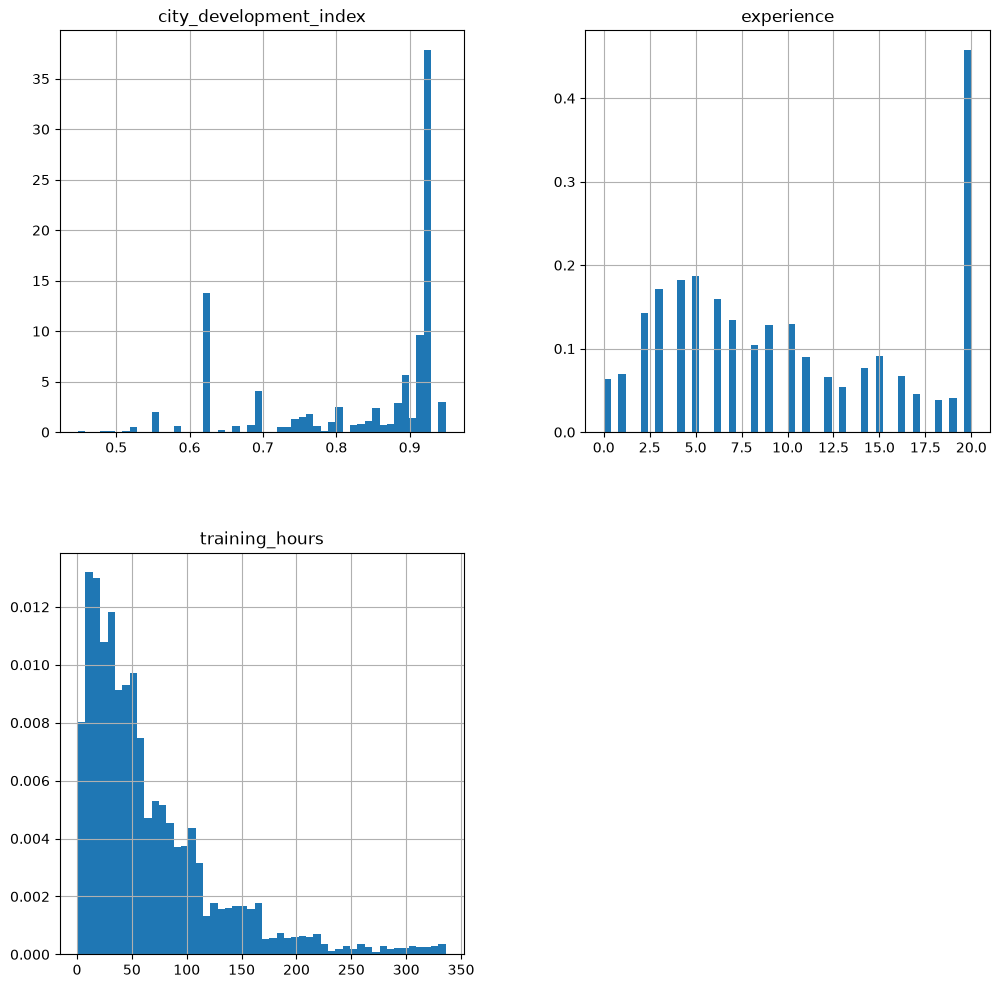

In [37]:
new_DS.hist(bins= 50, density= True, figsize= (12, 12))
plt.show()

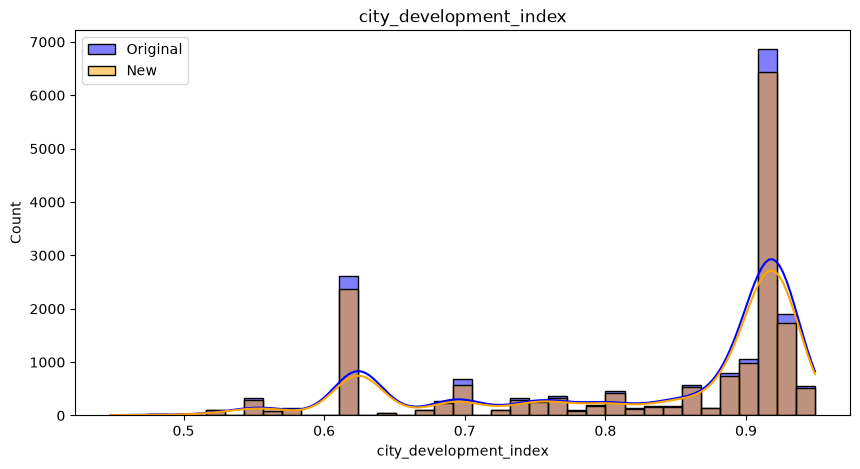

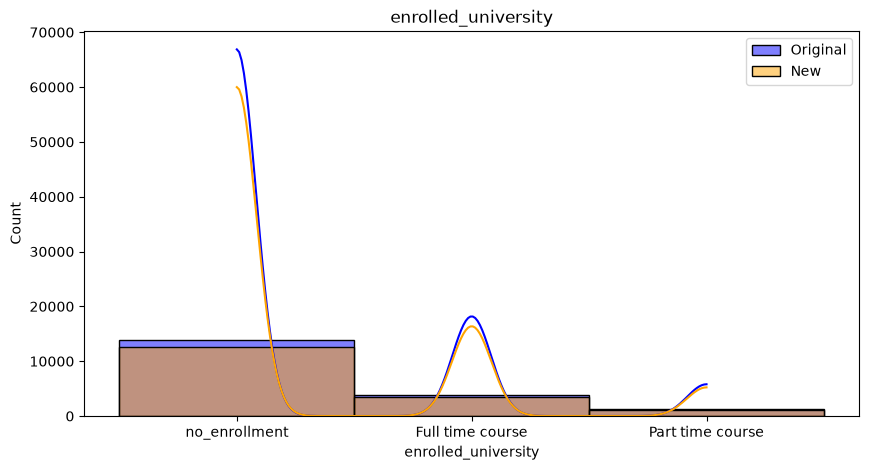

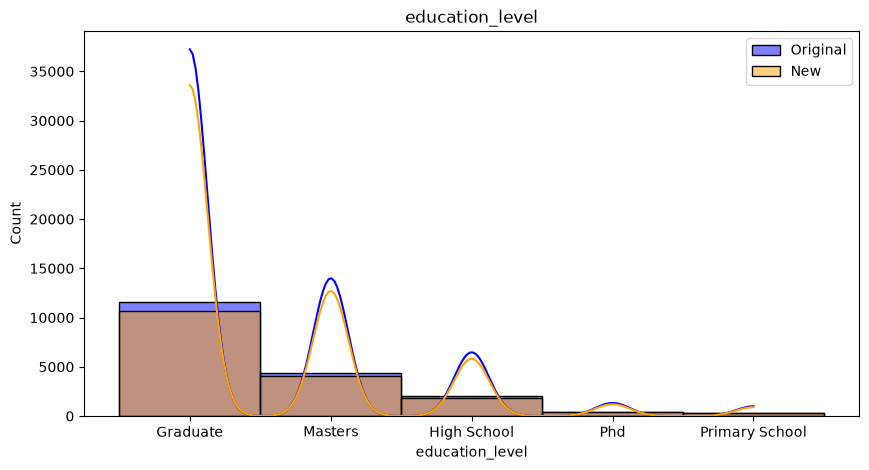

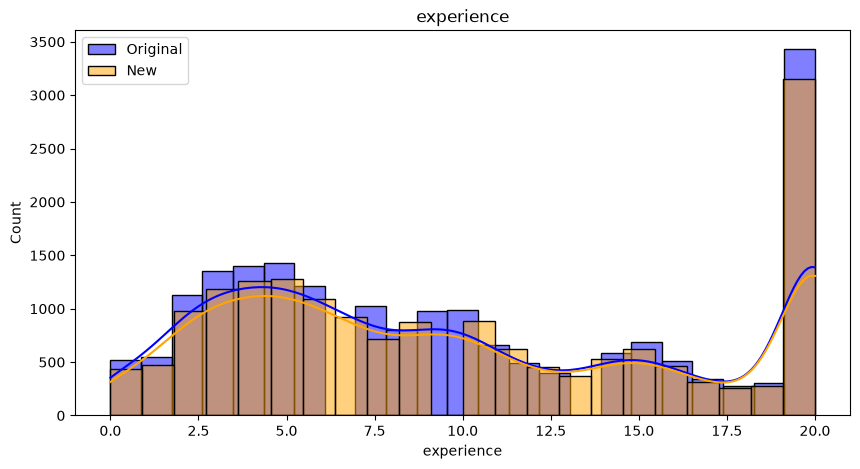

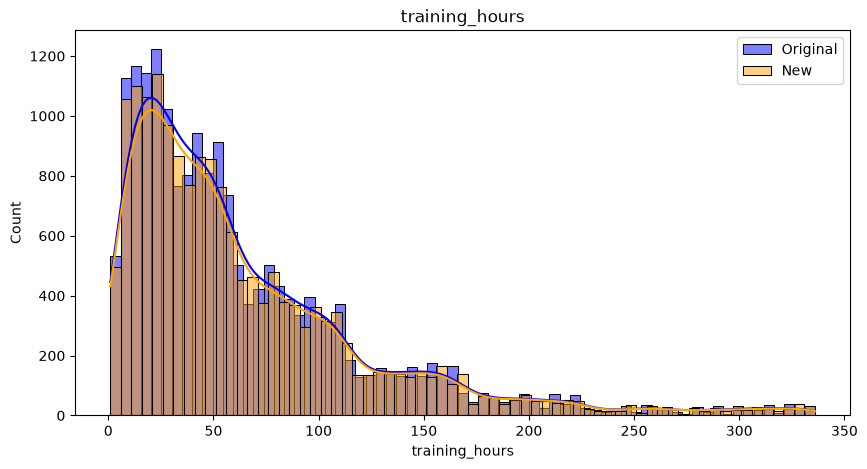

In [56]:

for val in col:
    
    plt.figure(figsize= (10,5)) 
    
    # plt.subplot(1,2,1)
    sns.histplot(data= DS, x= val, kde= True, color= "Blue", label= "Original", alpha= 0.5)
    
    # plt.subplot(1,2,2)
    sns.histplot(data= new_DS, x= val, kde= True, color= "orange", label= "New", alpha= 0.5) 
    
    plt.title(val)
    plt.legend()
    plt.show()

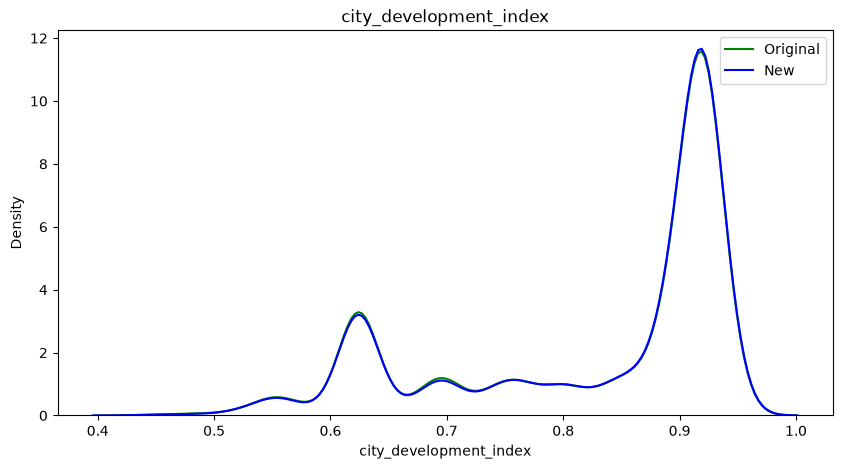

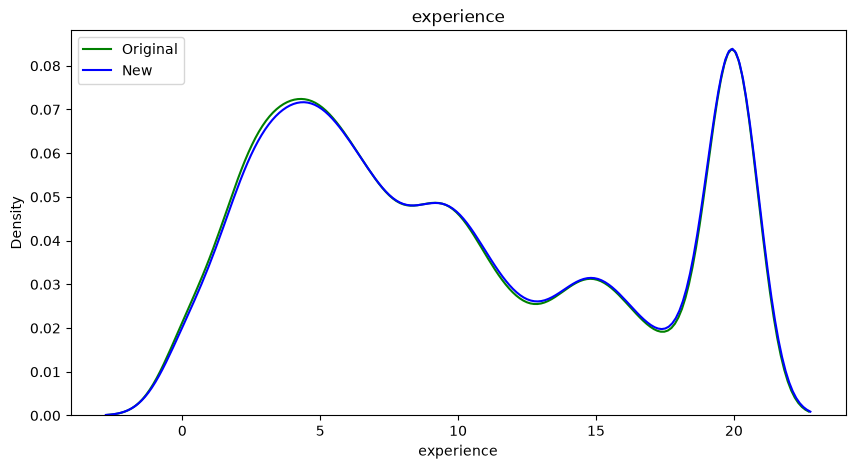

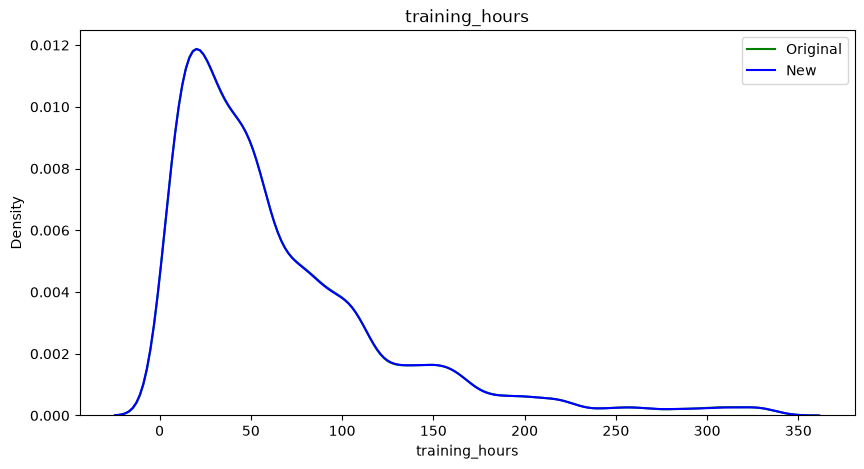

In [62]:
numeric_cols = DS[col].select_dtypes(include="number").columns

for val in numeric_cols:
    
    plt.figure(figsize= (10,5)) 
    
    # plt.subplot(1,2,1)
    sns.kdeplot(data= DS, x= val, color= "Green", label= "Original")
    
    # plt.subplot(1,2,2)
    sns.kdeplot(data= new_DS, x= val, color= "Blue", label= "New")
    
    plt.title(val)
    plt.legend()
    plt.show()